# Start the live VLM demo

**Settings:** Accelerator → GPU T4 x2, Internet → On. Then **Run all** and wait (~5 min).
The last cells print the public address and a QR code for the phone.

How it was built, step by step: `my-demo/vlm-demo.ipynb` in the same repo.

In [1]:
REPO = "https://github.com/Vigilume/vlm-surveillance-bench.git"
CODE = "/kaggle/working/vlm-surveillance-bench"
PAGES = f"{CODE}/my-demo"                 # index.html, live.html, static/ are served from here

!rm -rf {CODE}
!git clone -q --depth 1 {REPO} {CODE}
!ls {PAGES} {PAGES}/static

# Ollama (zstd unpacks it), Python packages, Cloudflare tunnel
!apt-get update -qq && apt-get install -y -qq zstd > /dev/null
!curl -fsSL https://ollama.com/install.sh | sh > /dev/null
!pip install -q ollama fastapi uvicorn python-multipart qrcode
!wget -q -O /usr/local/bin/cloudflared https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
!chmod +x /usr/local/bin/cloudflared
!nvidia-smi --query-gpu=index,name,memory.total --format=csv

/kaggle/working/vlm-surveillance-bench/my-demo:
index.html  live.html  static  vlm-demo.ipynb

/kaggle/working/vlm-surveillance-bench/my-demo/static:
app.js	live.js  style.css
W: https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%#############################                            63.9%##################################################                81.9%##################################          90.2%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding cu

In [2]:
import os, subprocess, time, requests, threading
import ollama

MODEL = "qwen3.5:9b"

def start_ollama(gpu, port):
    """Start one Ollama server that sees only one GPU and listens on its own port."""
    env = os.environ.copy()
    env["CUDA_VISIBLE_DEVICES"]  = str(gpu)
    env["OLLAMA_HOST"]           = f"127.0.0.1:{port}"
    env["OLLAMA_CONTEXT_LENGTH"] = "8192"
    env["OLLAMA_KEEP_ALIVE"]     = "-1"
    log = open(f"/kaggle/working/ollama_gpu{gpu}.log", "w")
    process = subprocess.Popen(["ollama", "serve"], env=env, stdout=log, stderr=subprocess.STDOUT)
    for _ in range(60):
        try:
            v = requests.get(f"http://127.0.0.1:{port}/api/version", timeout=2).json()["version"]
            print(f"GPU {gpu}: Ollama running on port {port}, version {v}")
            return process
        except requests.exceptions.RequestException:
            time.sleep(1)
    raise RuntimeError(f"GPU {gpu}: Ollama did not start; see /kaggle/working/ollama_gpu{gpu}.log")

subprocess.run(["pkill", "-f", "ollama"], stderr=subprocess.DEVNULL)
time.sleep(3)
servers = {0: start_ollama(0, 11434), 1: start_ollama(1, 11435)}
clients = {0: ollama.Client(host="127.0.0.1:11434"), 1: ollama.Client(host="127.0.0.1:11435")}

# Download once (both servers read the same files on disk)
for update in clients[0].pull(MODEL, stream=True):
    if update.get("status") == "success":
        print("Model downloaded:", MODEL)

# Warm up both GPUs AT THE SAME TIME (each loads its copy; ~2 min after a fresh start)
def warm_up(gpu):
    start = time.time()
    clients[gpu].chat(model=MODEL, messages=[{"role": "user", "content": "Say hi."}], think=False)
    print(f"GPU {gpu} warm in {time.time() - start:.0f} s")

threads = [threading.Thread(target=warm_up, args=(gpu,)) for gpu in clients]
for t in threads: t.start()
for t in threads: t.join()

!OLLAMA_HOST=127.0.0.1:11434 ollama ps
!OLLAMA_HOST=127.0.0.1:11435 ollama ps

GPU 0: Ollama running on port 11434, version 0.40.10
GPU 1: Ollama running on port 11435, version 0.40.10
Model downloaded: qwen3.5:9b
GPU 0 warm in 106 s
GPU 1 warm in 106 s
]11;?\NAME          ID              SIZE      PROCESSOR    CONTEXT    RUNNER      UNTIL   
qwen3.5:9b    56671c2ab938    5.9 GB    100% GPU     8192       llamacpp    Forever    
]11;?\NAME          ID              SIZE      PROCESSOR    CONTEXT    RUNNER      UNTIL   
qwen3.5:9b    56671c2ab938    5.9 GB    100% GPU     8192       llamacpp    Forever    


In [3]:
QUESTION_MANY  = ("These {n} images are frames from one security camera video, in time order, "
                  "about {gap:.2f} seconds apart. Describe what happens in 1-2 sentences. "
                  "Only describe what is clearly visible. Plain text, no introduction.")
QUESTION_ONE   = ("This image is one frame from a security camera video. Describe what is visible "
                  "in 1-2 sentences. Only describe what is clearly visible. Plain text, no introduction.")
QUESTION_SHORT = ("These {n} images are frames from one fixed camera, in time order, "
                  "about {gap:.2f} seconds apart. In ONE short sentence (at most 20 words), "
                  "say what happens. Plain text.")

def ask_gpu(gpu, frames, gap, short=False):
    """Ask the model on one GPU about a list of frames (JPEG bytes). Returns (answer, timing)."""
    if short:
        question, limit = QUESTION_SHORT.format(n=len(frames), gap=gap), 40
    elif len(frames) == 1:
        question, limit = QUESTION_ONE, 120
    else:
        question, limit = QUESTION_MANY.format(n=len(frames), gap=gap), 120
    start = time.time()
    r = clients[gpu].chat(
        model=MODEL,
        messages=[{"role": "user", "content": question, "images": frames}],
        think=False,
        options={"temperature": 0, "num_predict": limit},
    )
    timing = {
        "gpu":           gpu,
        "total_s":       round(time.time() - start, 2),
        "reading_s":     round(r["prompt_eval_duration"] / 1e9, 2),
        "writing_s":     round(r["eval_duration"] / 1e9, 2),
        "input_tokens":  r["prompt_eval_count"],
        "answer_tokens": r["eval_count"],
    }
    return r["message"]["content"], timing


class Dispatcher:
    """Taking turns between GPUs; one waiting slot; newest segment wins."""
    def __init__(self, gpus, on_result):
        self.gpus = list(gpus)
        self.on_result = on_result
        self.cond = threading.Condition()   # lock + doorbell
        self.waiting = None                 # the ONE segment waiting for a GPU
        self.busy = {g: False for g in self.gpus}
        self.turn = 0
        self.dropped = 0
        for g in self.gpus:
            threading.Thread(target=self._worker, args=(g,), daemon=True).start()

    def submit(self, segment):
        with self.cond:
            if self.waiting is not None:            # an older segment is waiting -> drop it
                self.dropped += 1
                self.waiting["dropped"] = True
                if "done" in self.waiting:          # wake up the request that sent it
                    self.waiting["done"].set()
            self.waiting = segment
            self.cond.notify_all()

    def _may_take(self, gpu):
        if self.waiting is None:
            return False
        preferred = self.gpus[self.turn]
        return gpu == preferred or self.busy[preferred]

    def _worker(self, gpu):
        while True:
            with self.cond:
                self.cond.wait_for(lambda: self._may_take(gpu))
                segment = self.waiting
                self.waiting = None
                self.busy[gpu] = True
                self.turn = (self.gpus.index(gpu) + 1) % len(self.gpus)
            segment["started"] = time.time()
            answer, timing = ask_gpu(gpu, segment["frames"], segment["gap"], segment.get("short", False))
            with self.cond:
                self.busy[gpu] = False
                self.cond.notify_all()
            self.on_result(segment, answer, timing)


def on_done(segment, answer, timing):
    segment["answer"] = answer
    segment["timing"] = timing
    segment["done"].set()

server_dispatcher = Dispatcher(gpus=[0, 1], on_result=on_done)
print("dispatcher ready")

dispatcher ready


In [4]:
import itertools, uvicorn
from typing import List, Annotated
from fastapi import FastAPI, File, Form, UploadFile
from fastapi.responses import FileResponse, JSONResponse
from fastapi.staticfiles import StaticFiles

app = FastAPI()
segment_ids = itertools.count(1)

@app.get("/hello")
def hello(name: str = "friend"):
    return {"message": f"hi {name}", "gpus": list(clients.keys())}

@app.get("/")
def clip_page():
    return FileResponse(f"{PAGES}/index.html")

@app.get("/live")
def live_page():
    return FileResponse(f"{PAGES}/live.html")

app.mount("/static", StaticFiles(directory=f"{PAGES}/static"), name="static")

@app.post("/analyze_frames")
def analyze_frames(frames: Annotated[List[UploadFile], File()],
                   gap:    Annotated[float, Form()] = 0.75,
                   short:  Annotated[bool, Form()] = False):
    received = time.time()
    if not 1 <= len(frames) <= 16:
        return JSONResponse({"error": "send between 1 and 16 frames"}, status_code=400)
    segment = {"id": next(segment_ids),
               "frames": [f.file.read() for f in frames],
               "gap": gap,
               "short": short,
               "ready": received,
               "done": threading.Event()}
    server_dispatcher.submit(segment)
    if not segment["done"].wait(timeout=60):
        return JSONResponse({"error": "timed out"}, status_code=504)
    if segment.get("dropped"):
        return {"id": segment["id"], "dropped": True}
    return {"id":       segment["id"],
            "dropped":  False,
            "answer":   segment["answer"],
            "gpu":      segment["timing"]["gpu"],
            "waited_s": round(segment["started"] - received, 2),
            "timing":   segment["timing"],
            "server_s": round(time.time() - received, 2)}

@app.post("/analyze_clip")
def analyze_clip(frames: Annotated[List[UploadFile], File()],
                 gap:    Annotated[float, Form()] = 0.75):
    with server_dispatcher.cond:
        both_busy = all(server_dispatcher.busy.values())
        someone_waiting = server_dispatcher.waiting is not None
    if both_busy and someone_waiting:
        return JSONResponse({"error": "busy, try again in a few seconds"}, status_code=429)
    return analyze_frames(frames=frames, gap=gap)

if "web_server" in globals():
    web_server.should_exit = True
    time.sleep(2)
web_server = uvicorn.Server(uvicorn.Config(app, host="127.0.0.1", port=8000, log_level="warning"))
threading.Thread(target=web_server.run, daemon=True).start()
time.sleep(2)
print("server started on port 8000")

server started on port 8000


In [5]:
import cv2, numpy as np

def test_frame(t):
    """A fake camera frame: a blue box that moves right as t grows. Returns JPEG bytes."""
    frame = np.full((288, 512, 3), 45, dtype=np.uint8)
    x = int(20 + 72 * t)
    cv2.rectangle(frame, (x, 100), (x + 40, 230), (200, 90, 30), -1)
    return cv2.imencode(".jpg", frame)[1].tobytes()

for path in ("/", "/live", "/static/live.js"):
    print(path, requests.get(f"http://127.0.0.1:8000{path}").status_code)

files = [("frames", (f"f{k}.jpg", test_frame((k + 0.5) * 0.75), "image/jpeg")) for k in range(8)]
r = requests.post("http://127.0.0.1:8000/analyze_frames", files=files,
                  data={"gap": 0.75, "short": True}).json()
print(f"GPU {r['gpu']} · {r['timing']['total_s']} s · {r['answer']}")

/ 200
/live 200
/static/live.js 200
GPU 0 · 9.04 s · A blue rectangle moves from the left side of the screen to the right side.


Live mode: https://household-pasta-everyone-johnson.trycloudflare.com/live
Clip mode: https://household-pasta-everyone-johnson.trycloudflare.com


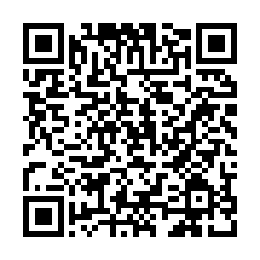

In [6]:
import re, qrcode
from IPython.display import display

subprocess.run(["pkill", "-f", "cloudflared"], stderr=subprocess.DEVNULL)
tunnel = subprocess.Popen(["cloudflared", "tunnel", "--no-autoupdate", "--url", "http://127.0.0.1:8000"],
                          stdout=open("/kaggle/working/tunnel.log", "w"), stderr=subprocess.STDOUT)

PUBLIC_URL = None
for _ in range(60):
    found = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", open("/kaggle/working/tunnel.log").read())
    if found:
        PUBLIC_URL = found.group(0)
        break
    time.sleep(1)
if PUBLIC_URL is None:
    raise RuntimeError("No tunnel address; see /kaggle/working/tunnel.log")

# A new address needs a few seconds before it works from outside: try until it answers
for _ in range(30):
    try:
        if requests.get(f"{PUBLIC_URL}/hello", timeout=5).ok:
            break
    except requests.exceptions.RequestException:
        pass
    time.sleep(2)

LIVE_URL = f"{PUBLIC_URL}/live"
print("Live mode:", LIVE_URL)
print("Clip mode:", PUBLIC_URL)
display(qrcode.make(LIVE_URL).get_image().resize((260, 260)))

In [7]:
try:
    while True:
        busy = [g for g, b in server_dispatcher.busy.items() if b]
        print(f"{time.strftime('%H:%M:%S')} · {LIVE_URL} · GPUs busy: {busy} · dropped: {server_dispatcher.dropped}",
              flush=True)
        time.sleep(60)
except KeyboardInterrupt:
    print("keep-alive stopped")

09:57:16 · https://household-pasta-everyone-johnson.trycloudflare.com/live · GPUs busy: [] · dropped: 0
09:58:16 · https://household-pasta-everyone-johnson.trycloudflare.com/live · GPUs busy: [] · dropped: 0
09:59:16 · https://household-pasta-everyone-johnson.trycloudflare.com/live · GPUs busy: [] · dropped: 0
10:00:16 · https://household-pasta-everyone-johnson.trycloudflare.com/live · GPUs busy: [] · dropped: 0
keep-alive stopped
